# Gillespie kMC of a pseudo-first-order decay

**Reaction:** A + B → C, with B in large excess (B is consumed, but barely changes).

Because [B] barely changes, the rate law simplifies:

$$\frac{d[A]}{dt} = -k[A][B] \approx -k'[A], \qquad k' = k[B]_0$$

so deterministically $[A](t) = [A]_0 e^{-k't}$ (*pseudo*-first-order).

With only a few molecules, decay is random. The **Gillespie direct method** simulates this exactly. With reaction channels $j$ and propensities $a_j$, and $a_0 = \sum_j a_j$:

1. Waiting time to the next event: $\tau = -\ln(u_1)/a_0$
2. **Event selection:** pick reaction $j$ with probability $a_j/a_0$ (using a second random number $u_2$)
3. Apply it: $x \to x + \text{stoich}_j$
4. Repeat until nothing can happen

The decay has one channel ($a = k'N$), so step 2 is trivial *there*; sections 5–6 exercise it properly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from gillespie_decay import (effective_rate, simulate_decay, simulate_runs, simulate_ensemble,
                             simulate_explicit_b, gillespie_direct, counts_on_grid,
                             analytical_mean, analytical_std, standardized_residuals,
                             estimate_rate, Z_TOLERANCE)

K, CONC_B = 0.1, 0.5            # k in 1/(M s), [B] in M
K_EFF = effective_rate(K, CONC_B)
N0 = 100
print(f"k' = {K_EFF} 1/s, half-life = {np.log(2)/K_EFF:.1f} s")

k' = 0.05 1/s, half-life = 13.9 s


## 1. One trajectory
Each step down is one molecule reacting. Steps get *longer* as fewer molecules remain, because the propensity $k'N$ shrinks.

first 5 event times: [0.203 0.211 0.554 0.746 0.909]
last event time: 172.4 s


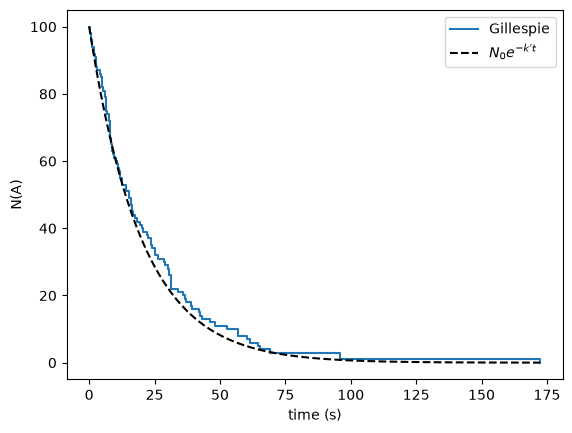

In [2]:
rng = np.random.default_rng(0)
times, counts = simulate_decay(N0, K_EFF, rng)
print("first 5 event times:", np.round(times[1:6], 3))
print("last event time:", round(times[-1], 1), "s")

t = np.linspace(0, times[-1], 400)
plt.step(times, counts, where="post", label="Gillespie")
plt.plot(t, analytical_mean(t, N0, K_EFF), "k--", label=r"$N_0 e^{-k't}$")
plt.xlabel("time (s)"); plt.ylabel("N(A)"); plt.legend(); plt.show()

## 2. Many trajectories: does the average recover the rate law?
Every molecule survives to time $t$ independently with probability $e^{-k't}$, so $N(t)$ is Binomial($N_0$, $e^{-k't}$): mean $N_0 p$, variance $N_0 p (1-p)$.

"Looks close" is not a test, so we compute the z-score of the simulated mean against the exact mean at every time, in units of its standard error. A correct simulation stays inside ±4.

max |z| = 1.73  ->  PASS


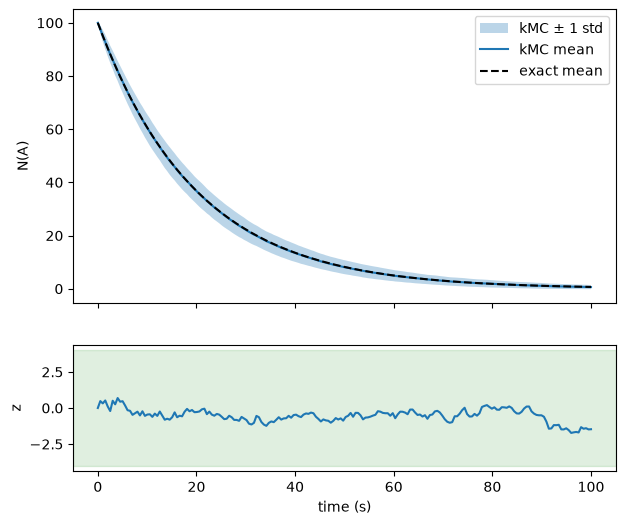

wrong-rate data: max |z| = 18.0  (should exceed 4.0)


In [3]:
grid = np.linspace(0, 100, 200)
ens = simulate_ensemble(N0, K_EFF, n_runs=500, grid=grid, seed=1)
mean, std = ens.mean(axis=0), ens.std(axis=0, ddof=1)
z = standardized_residuals(ens, grid, N0, K_EFF)
print(f"max |z| = {np.abs(z).max():.2f}  ->  {'PASS' if np.abs(z).max() < Z_TOLERANCE else 'FAIL'}")

fig, (ax, axz) = plt.subplots(2, 1, figsize=(7, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
ax.fill_between(grid, mean-std, mean+std, alpha=0.3, label="kMC ± 1 std")
ax.plot(grid, mean, label="kMC mean")
ax.plot(grid, analytical_mean(grid, N0, K_EFF), "k--", label="exact mean")
ax.set_ylabel("N(A)"); ax.legend()
axz.axhspan(-Z_TOLERANCE, Z_TOLERANCE, color="green", alpha=0.12)
axz.plot(grid, z); axz.set_ylabel("z"); axz.set_xlabel("time (s)"); plt.show()

# The same check applied to data from a rate 10% too high must FAIL:
bad = simulate_ensemble(N0, 1.10*K_EFF, n_runs=500, grid=grid, seed=1)
print(f"wrong-rate data: max |z| = {np.abs(standardized_residuals(bad, grid, N0, K_EFF)).max():.1f}  (should exceed {Z_TOLERANCE})")

## 3. Recover $k'$ from the simulated data, with an uncertainty
The $N_0$ event times of a completed run are the order statistics of $N_0$ independent Exp($k'$) lifetimes. Pooling all lifetimes gives the unbiased maximum-likelihood estimate $\hat k' = (n-1)/\sum t_i$ with standard error $\hat k'/\sqrt{n-2}$.

A bare "error of 0.5 %" would mean nothing here: with $n = 50\,000$ lifetimes the standard error is already ≈ 0.45 %.

In [4]:
runs = simulate_runs(N0, K_EFF, 500, seed=2024)
est = estimate_rate(np.concatenate([t[1:] for t, _ in runs]))
print(f"k' = {est.k_hat:.5f} ± {est.se:.5f} 1/s (s.e.), 95% CI [{est.ci_low:.5f}, {est.ci_high:.5f}]")
print(f"true k' = {K_EFF}, z = {(est.k_hat-K_EFF)/est.se:+.2f}")

k' = 0.05025 ± 0.00022 1/s (s.e.), 95% CI [0.04981, 0.05070]
true k' = 0.05, z = +1.13


## 4. Noise shrinks with system size
The relative fluctuation at the half-life is $1/\sqrt{N_0}$, so the deterministic law is the large-$N$ limit of the stochastic one.

In [5]:
t_half = np.log(2)/K_EFF
for n0 in [10, 100, 1000]:
    e = simulate_ensemble(n0, K_EFF, 300, np.array([t_half]), seed=2)[:, 0]
    print(f"N0={n0:5d}: relative std at t_half = {e.std(ddof=1)/e.mean():.3f}   (theory {1/np.sqrt(n0):.3f})")

N0=   10: relative std at t_half = 0.313   (theory 0.316)
N0=  100: relative std at t_half = 0.103   (theory 0.100)


N0= 1000: relative std at t_half = 0.031   (theory 0.032)


## 5. Event selection with two channels: A ⇌ C
Forward rate $k_f = 0.3$, backward $k_b = 0.1$. The engine must choose between the channels with probability $a_j/a_0$; the equilibrium fraction of A should be $k_b/(k_f+k_b) = 0.25$. Always choosing channel 0 would empty A; choosing uniformly would give 0.5.

In [6]:
kf, kb, n = 0.3, 0.1, 20
stoich = [[-1, 1], [1, -1]]
prop = lambda x: np.array([kf*x[0], kb*x[1]])
rng = np.random.default_rng(3)
final_a = np.array([gillespie_direct([n, 0], stoich, prop, rng, t_max=20.0).states[-1, 0] for _ in range(1000)])
p = kb/(kf+kb)
print(f"mean A fraction at t=20: {final_a.mean()/n:.3f} ± {final_a.std(ddof=1)/np.sqrt(1000)/n:.3f}   (theory {p:.3f})")

mean A fraction at t=20: 0.254 ± 0.003   (theory 0.250)


## 6. When does "pseudo-first-order" break down?
`simulate_explicit_b` simulates B molecules explicitly (A + B → C, B consumed), with $c = k'/N_{B0}$ so that $c N_{B0} = k'$. The approximation should hold when $N_{B0} \gg N_{A0}$ and fail otherwise.

In [7]:
n0 = 50
for ratio in [100, 10, 1]:
    rng = np.random.default_rng(4)
    ens = np.array([counts_on_grid(*simulate_explicit_b(n0, ratio*n0, K_EFF, rng), grid) for _ in range(500)])
    zmax = np.abs(standardized_residuals(ens, grid, n0, K_EFF)).max()
    print(f"N_B0/N_A0 = {ratio:4d}: max |z| vs exp(-k't) = {zmax:6.1f}  -> {'consistent' if zmax < Z_TOLERANCE else 'pseudo-first-order FAILS'}")

N_B0/N_A0 =  100: max |z| vs exp(-k't) =    1.5  -> consistent


N_B0/N_A0 =   10: max |z| vs exp(-k't) =    7.9  -> pseudo-first-order FAILS


N_B0/N_A0 =    1: max |z| vs exp(-k't) =  301.3  -> pseudo-first-order FAILS
